# 1. Introduction 

Life expectancy is an essential measure of a nation’s health and development. Many influences may determine life expectancy, which can range from socioeconomic circumstances to public health initiatives and prevalence of illness. In this analysis, we examine a dataset comprised of vital health and demographic indicators from countries around the world, with a particular emphasis on the variables that could affect an individual’s life expectancy. In this particular dataset, there are variables such as adult mortality, infant deaths, alcohol consumption, vaccination coverage, gross domestic product, schooling, and various other variables. An exploratory data analysis (EDA) would help to identify patterns and relationships between the predictors and life expectancy. Knowing the relationships would provide insights into the challenges of improving public health and longevity across various nations and inform decisions around spending on health access, disease prevention, and education, among others. 

# 2. Importing Relevant Libraries

In [106]:
import numpy as np 
import pandas as pd
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objs as go
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler,  LabelEncoder
from sklearn.preprocessing import StandardScaler as ss
#from fbprophet import Prophet
from prophet import Prophet
import pycountry
import pycountry_convert as pc
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=Warning)

# 3. Reading and Cleaning The Data

In [6]:
df = pd.read_csv("Life Expectancy Data.csv")

In [7]:
#df['Year'] = pd.to_datetime(df['Year'], format='%Y')

# Set the 'Year' column as the index
#df.set_index('Year', inplace=True)

In [8]:
#renaming the columns
df.rename(columns = {'Year':'year','Life expectancy ':'life_expectancy','Adult Mortality':'adult_mortality',
                      'infant deaths':'infant_deaths','Alcohol':'alcohol','percentage expenditure':'per_exp',
                      'Hepatitis B': 'hep_b','Measles ':'measles',' BMI ':'bmi',
                      'under-five deaths ':'under_5_deaths','Polio':'polio','Total expenditure':'total_exp',
                      'Diphtheria ':'diphtheria',' HIV/AIDS':'aids','GDP':'gdp','Population':'pop',
                      ' thinness  1-19 years':'thin_1_19_yrs',' thinness 5-9 years':'thin_5_9_yrs',
                      'Income composition of resources':'income_comp_resource','Schooling':'schooling',
                      'Country':'country', 'Status':'status'}, inplace = True)

In [9]:
#displaying the columns in the dataset
df.columns

Index(['country', 'year', 'status', 'life_expectancy', 'adult_mortality',
       'infant_deaths', 'alcohol', 'per_exp', 'hep_b', 'measles', 'bmi',
       'under_5_deaths', 'polio', 'total_exp', 'diphtheria', 'aids', 'gdp',
       'pop', 'thin_1_19_yrs', 'thin_5_9_yrs', 'income_comp_resource',
       'schooling'],
      dtype='object')

The column names were successfully changed

In [11]:
#displaying the first rows of the dataset
df.head() 

,country,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,per_exp,hep_b,measles,...,polio,total_exp,diphtheria,aids,gdp,pop,thin_1_19_yrs,thin_5_9_yrs,income_comp_resource,schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [12]:
#displaying the last rows of the dataset
df.tail()

,country,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,per_exp,hep_b,measles,...,polio,total_exp,diphtheria,aids,gdp,pop,thin_1_19_yrs,thin_5_9_yrs,income_comp_resource,schooling
2933,Zimbabwe,2004,Developing,44.3,723.0,27,4.36,0.0,68.0,31,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2934,Zimbabwe,2003,Developing,44.5,715.0,26,4.06,0.0,7.0,998,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2935,Zimbabwe,2002,Developing,44.8,73.0,25,4.43,0.0,73.0,304,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2936,Zimbabwe,2001,Developing,45.3,686.0,25,1.72,0.0,76.0,529,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8
2937,Zimbabwe,2000,Developing,46.0,665.0,24,1.68,0.0,79.0,1483,...,78.0,7.10,78.0,43.5,547.358878,12222251.0,11.0,11.2,0.434,9.8


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   country               2938 non-null   object 
 1   year                  2938 non-null   int64  
 2   status                2938 non-null   object 
 3   life_expectancy       2928 non-null   float64
 4   adult_mortality       2928 non-null   float64
 5   infant_deaths         2938 non-null   int64  
 6   alcohol               2744 non-null   float64
 7   per_exp               2938 non-null   float64
 8   hep_b                 2385 non-null   float64
 9   measles               2938 non-null   int64  
 10  bmi                   2904 non-null   float64
 11  under_5_deaths        2938 non-null   int64  
 12  polio                 2919 non-null   float64
 13  total_exp             2712 non-null   float64
 14  diphtheria            2919 non-null   float64
 15  aids                 

In [14]:
 # Transforming each column with an 'object' data type to a more memory-efficient data type'category'.
#for column in df.columns:
  #  if df[column].dtype == 'object':
  #      df[column] = df[column].astype('category')

In [15]:
#checking for missing values in the dataset
df.isna().sum()

country                   0
year                      0
status                    0
life_expectancy          10
adult_mortality          10
infant_deaths             0
alcohol                 194
per_exp                   0
hep_b                   553
measles                   0
bmi                      34
under_5_deaths            0
polio                    19
total_exp               226
diphtheria               19
aids                      0
gdp                     448
pop                     652
thin_1_19_yrs            34
thin_5_9_yrs             34
income_comp_resource    167
schooling               163
dtype: int64

The dataset has missing values, I will first use a heatmap to visualize the missing values, and then I will imputate the missing values using mean 

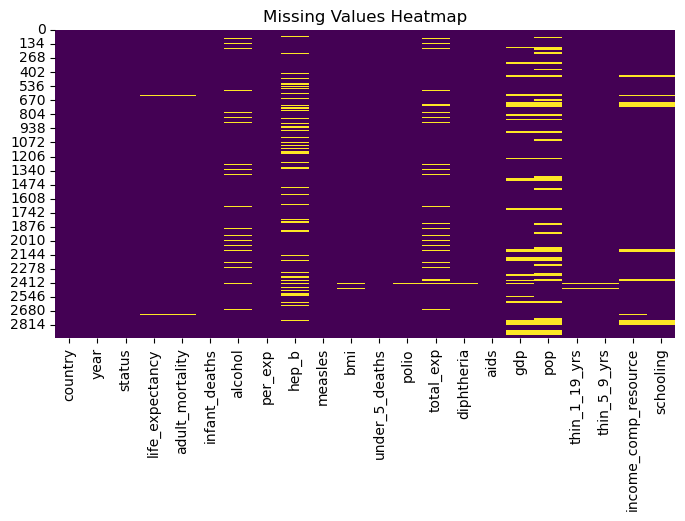

In [17]:
# Visualizing missing values with a heatmap
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

<h5>Observation</h5>

The heatmap shows that certain columns, such as Hepatitis B, Alcohol, Total expenditure, GDP, and Population, have a lot of missing values, while others like Life expectancy, Adult Mortality, and Schooling have fewer missing entries.

In [20]:
# Imputing missing numerical values using the mean of each column
df.fillna(df.mean(numeric_only=True), inplace=True)

# Verifying that no missing values remain in numerical columns
missing_values_after_imputation = df.isnull().sum()

missing_values_after_imputation

country                 0
year                    0
status                  0
life_expectancy         0
adult_mortality         0
infant_deaths           0
alcohol                 0
per_exp                 0
hep_b                   0
measles                 0
bmi                     0
under_5_deaths          0
polio                   0
total_exp               0
diphtheria              0
aids                    0
gdp                     0
pop                     0
thin_1_19_yrs           0
thin_5_9_yrs            0
income_comp_resource    0
schooling               0
dtype: int64

The missing values were successfully imputed with the mean

In [22]:
#checking if there are any duplicates in the dataset
print("Number of duplicates:", df.duplicated().sum())

Number of duplicates: 0


The dataset does not have any duplicates, now I will move to exploring the distribution across the data

#  4. Exploratory Data Analysis

<h3>4.1 Distributions</h3>

Creating a histogram to visualize distribution of 'Life expectancy' data.

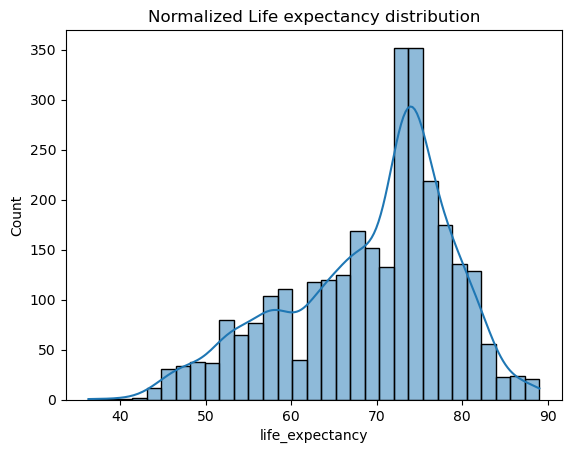

In [27]:
# Create seaborn histogram
sns.histplot(data=df, x="life_expectancy", kde=True, bins=31)

# Set plot title
plt.title('Normalized Life expectancy distribution')
plt.show()

<h5>Observation</h5>

This is an assymetric distibution - a majority of the observations appear to the right of the mean. The left tail is longer than the right. Therefore this is a distribution of a left skew (negative skewness).


Next, I will calculate the skewness value, it should return a negative value to prove that life expectancy distribution is negatively skewed

In [31]:
# Using pandas skew to calculate skew value to prove that the distribution is indeed negatively skewed
df['life_expectancy'].skew()

-0.6396932035944191

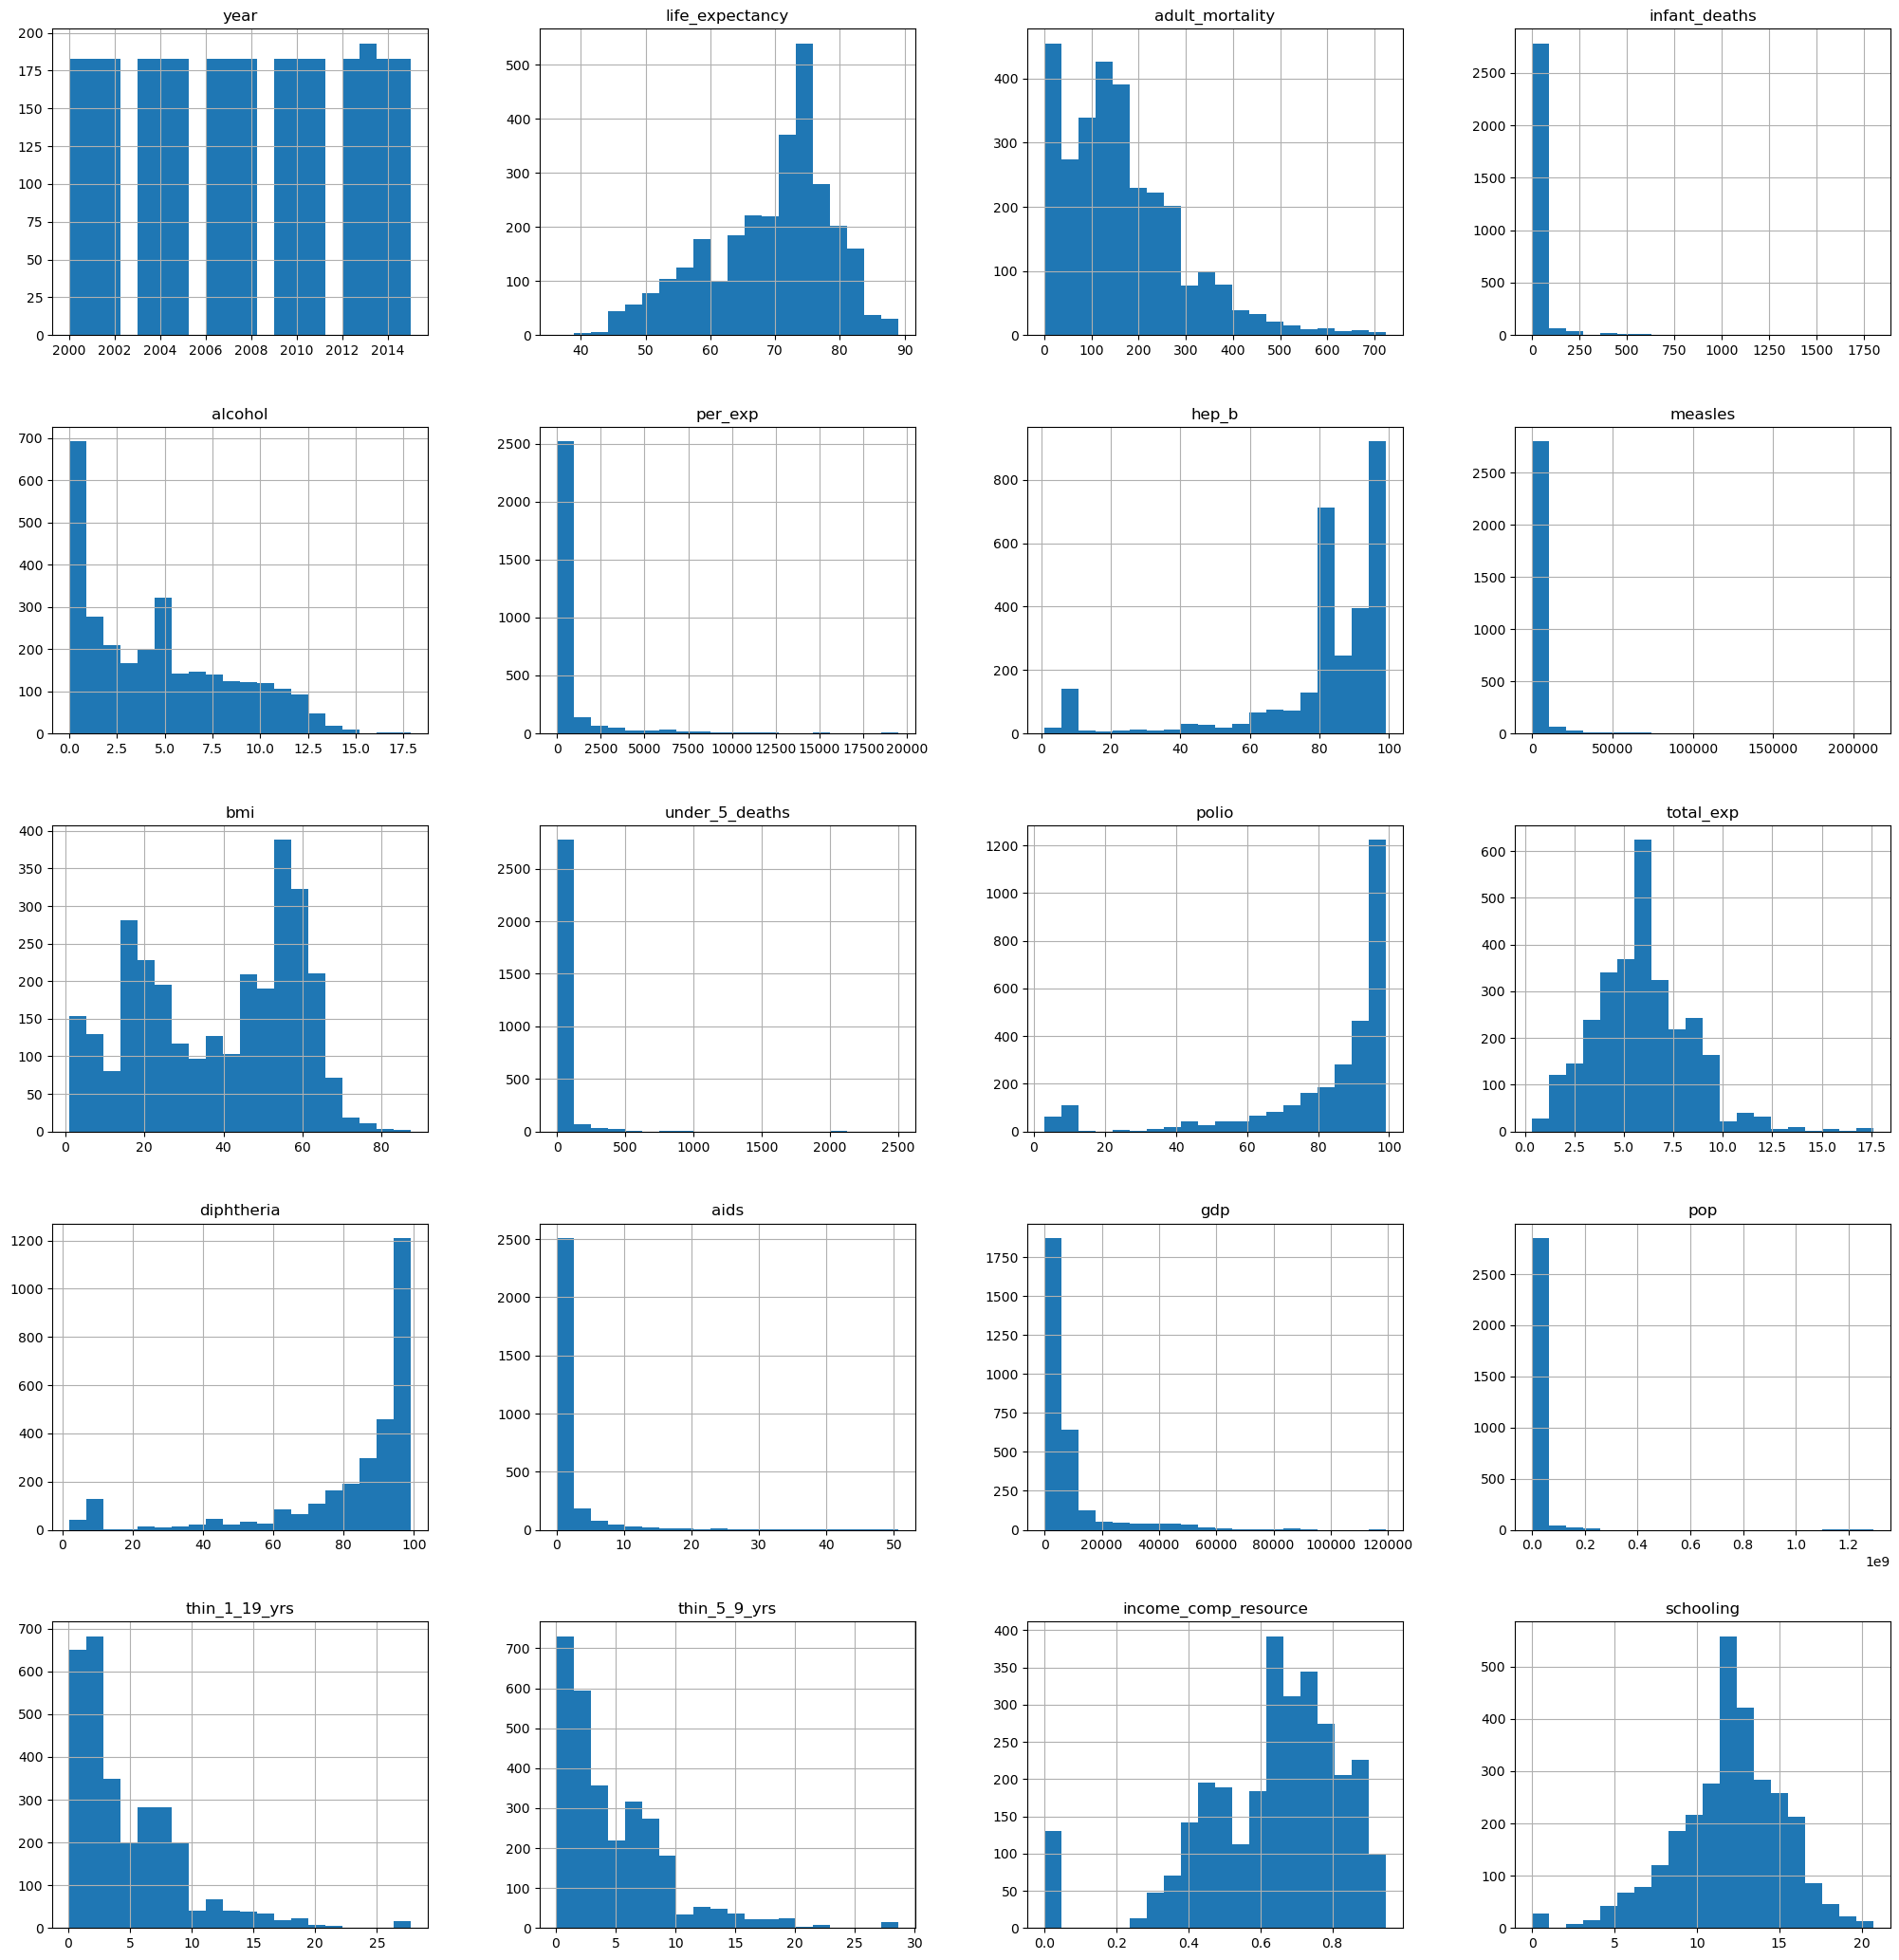

In [32]:
# exploring the distribution of the features
df.hist(bins=20, figsize=(25,26))
plt.show()

<h5>Observation</h5>
<h6>1.Life Expectancy:</h6>
Appears to have a roughly normal distribution, though negatively skewed.

<h6>2.Mortality (Adult Mortality, Infant Deaths, Under 5 Deaths):</h6>
These columns show highly skewed distributions, with many countries having lower values and a long tail of higher values.

<h6>3.Alcohol, BMI, Polio, Diphtheria, Hepatitis B:</h6>
These columns have a somewhat skewed distribution, especially Hepatitis B and Polio with peaks around the higher end of the spectrum.

<h6>4.Expenditure Columns (Total Expenditure, Per capita expenditure):</h6>
The distribution of expenditure data (total and per capita) seems to be skewed as well, with most values on the lower end and a few extreme values.

<h6>5.GDP, Population:</h6>
These distributions are heavily skewed, reflecting the fact that a few countries have much higher GDP and population sizes than the rest.

<h6>6.Schooling, Income Composition of Resources:</h6>
These show a more Gaussian distribution, with most of the values concentrated in the middle ranges.

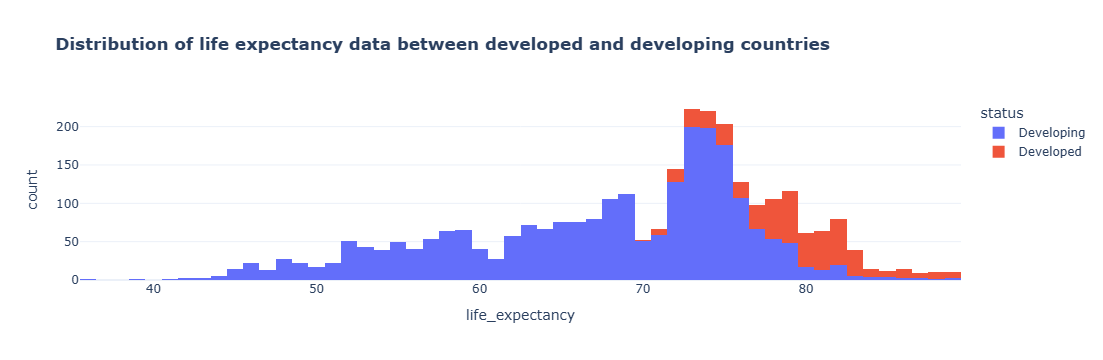

In [34]:
fig = px.histogram(df, 
                   x='life_expectancy', 
                   color='status', 
                   template='plotly_white', 
                   title='<b>Distribution of life expectancy data between developed and developing countries')
fig.show()

<h5>Observation</h5>
The distribution plot of life expectancy between developed and developing countries provides a clear visual of the differences. 

1.Developing Countries: The life expectancy is more spread out, with a significant number of countries having life expectancy between 40 to 60 years. There is a peak in the 60-70 year range, indicating many developing countries fall within this range.

2.Developed Countries: The life expectancy is clustered in the higher range, with most countries having life expectancy between 70 to 80 years.

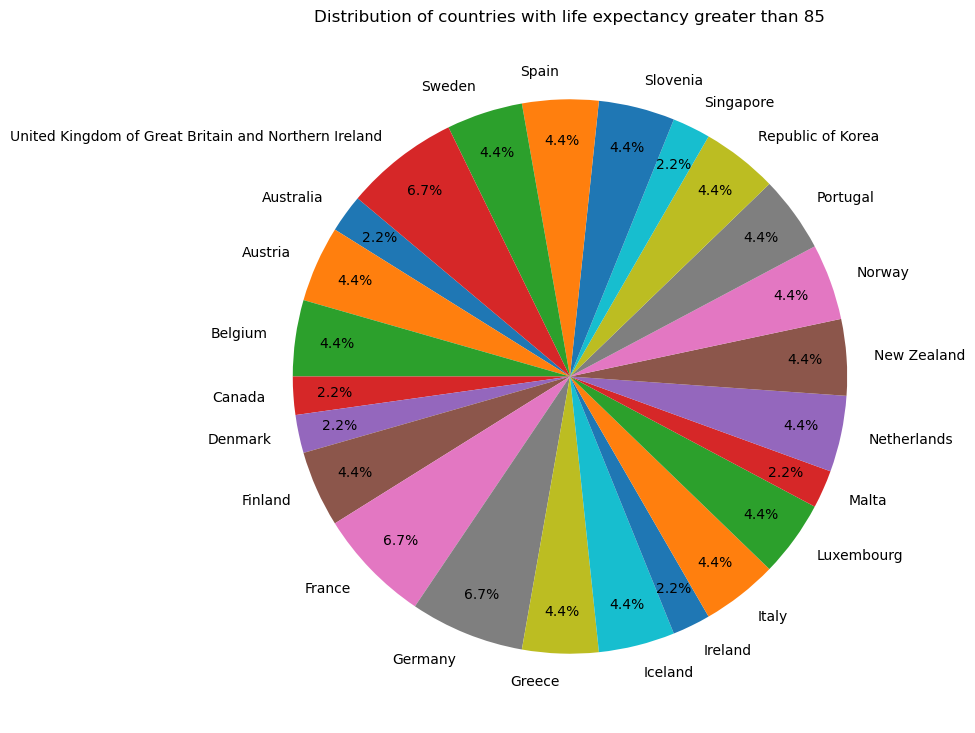

In [36]:
filter = df['life_expectancy'] > 85

filt = df.iloc[np.where(filter)]

group = filt.groupby('country').size()

plt.figure(figsize=(15,9))
plt.pie(group, labels=group.index,  pctdistance=0.85, labeldistance=1.1, autopct='%1.1f%%', startangle=140)
plt.title("Distribution of countries with life expectancy greater than 85")
plt.show()

<h5>Observation</h5>
<p>1.Countries such as France, Germany, and Spain have the highest proportion of 6.7%.</p>
<p>2.A majority of other countries, including Sweden, New Zealand, Norway, and others, share similar proportions of 4.4%.</p>
<p>3.Countries like Canada, Austria, and Denmark have the lowest proportion of 2.2%.</p>
This pie chart highlights the relatively small number of countries that achieve a life expectancy greater than 85, and shows that the proportions are distributed quite evenly, with no country dominating the majority of the data.

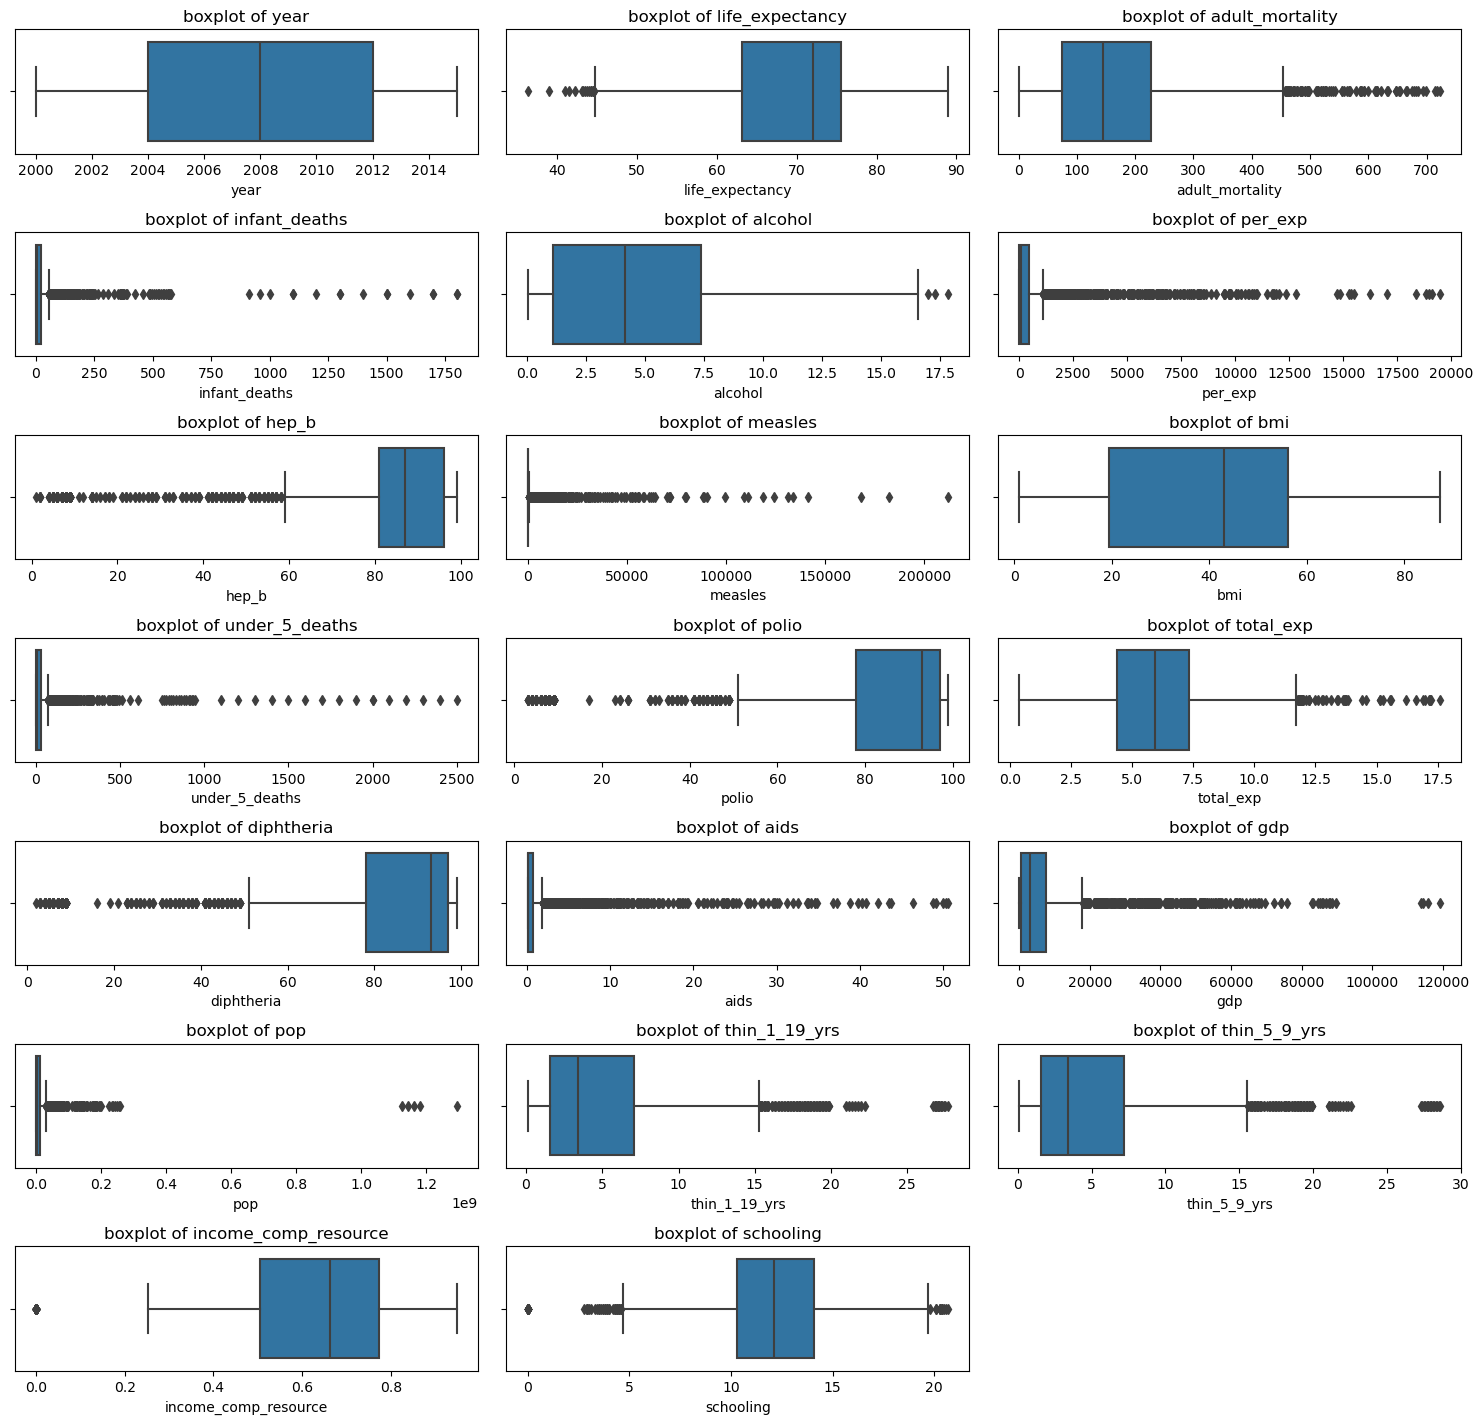

In [38]:
#boxplot of all the numeric columns
df_numerical = df.select_dtypes(include=['float64', 'int64'])
plt.figure(figsize=(15,20))
for i in range(len(df_numerical.columns)):
    plt.subplot(10,3,i+1)
    plt.title(f"boxplot of {df_numerical.columns[i]}")
    sns.boxplot(df_numerical,x = df_numerical.columns[i])
plt.tight_layout()
plt.show()

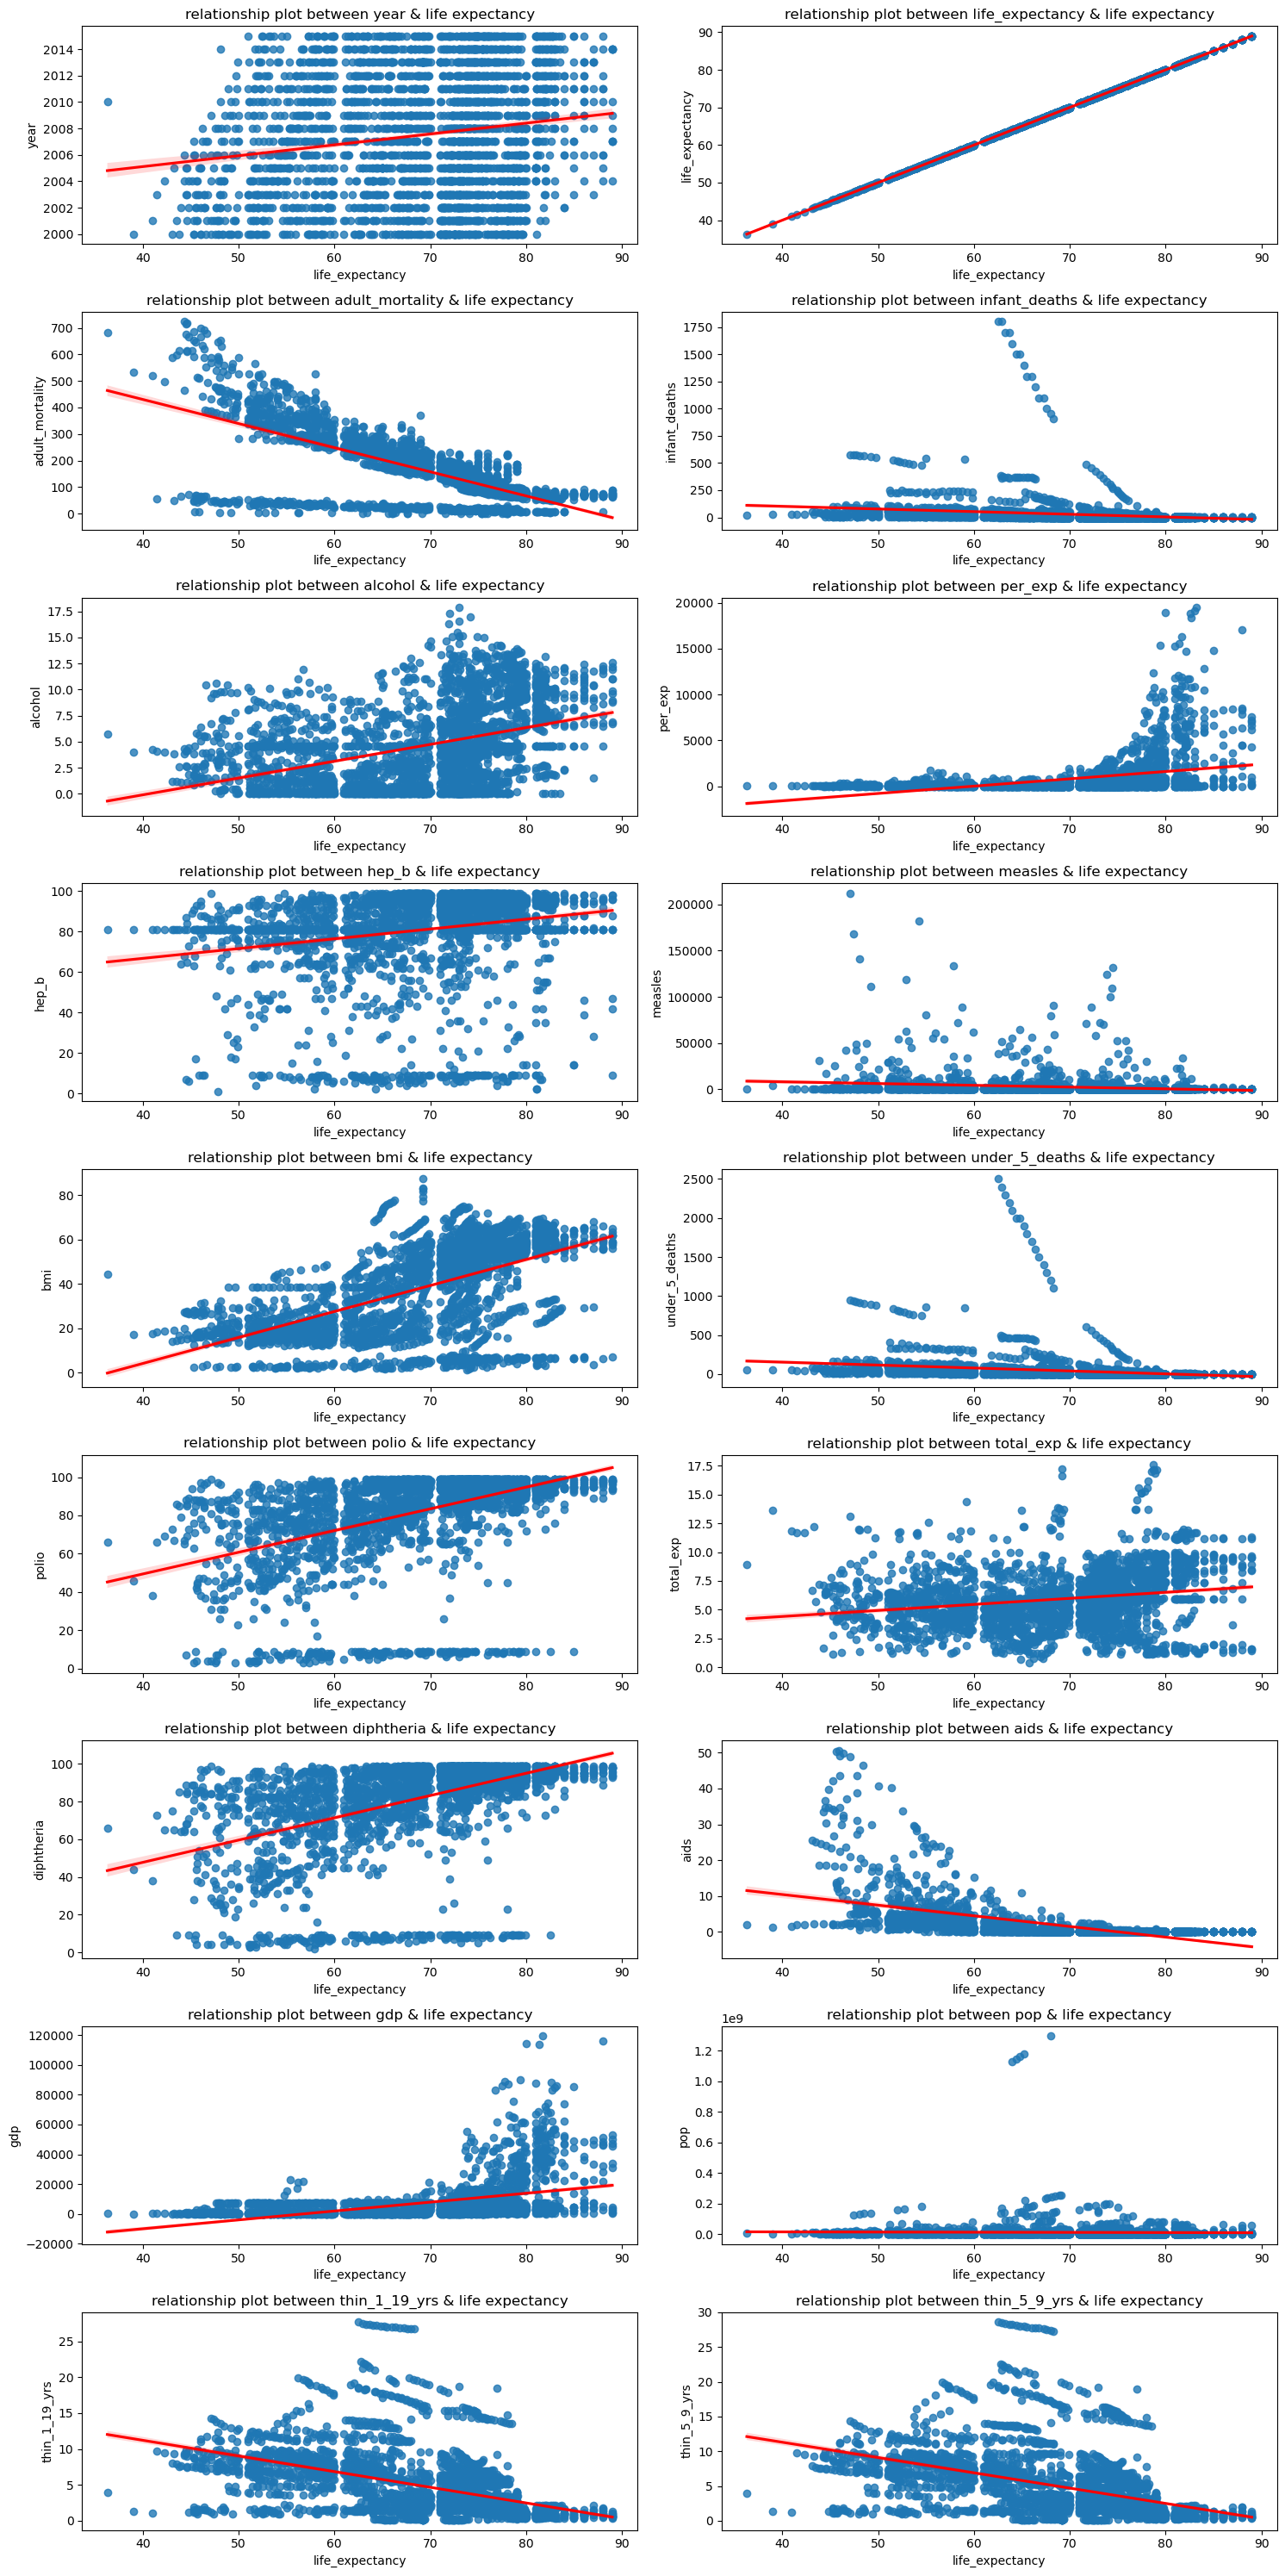

In [39]:
#plotting the relationship between life expectancy and other numerical columns
plt.figure(figsize=(15,30))
for i in range(len(df_numerical.columns)):
    if (i+1 == 19):
        break
    else:
        plt.subplot(9,2,i+1)
        plt.title(f"relationship plot between {df_numerical.columns[i]} & life expectancy")
        sns.regplot(df_numerical,y = df_numerical.columns[i], x = 'life_expectancy', line_kws = {'color' : 'r'})
plt.tight_layout()
plt.show()

<Axes: xlabel='adult_mortality', ylabel='life_expectancy'>

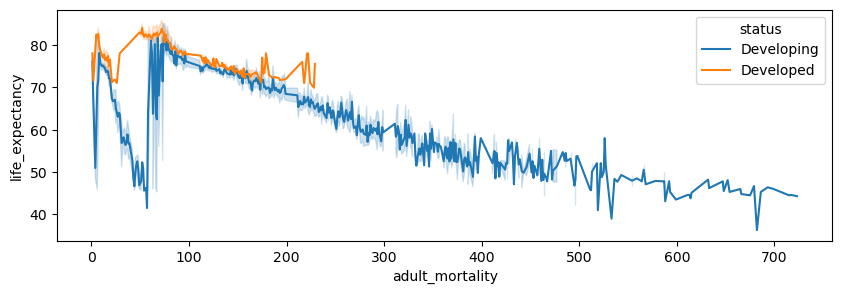

In [40]:
#lineplot of year vs life expectancy with respect to status
plt.figure(figsize = (10,3))
sns.lineplot(df,x = 'adult_mortality', y = 'life_expectancy',hue = 'status')

<h5>Observation</h5>
The line graph indicates that as adult mortality increases, life expectancy decreases. This suggests a negative correlation between adult mortality rates and life expectancy.
<p>1.Developing Countries have higher adult mortality rates and lower life expectancy</p>
<p>2.Developed Countries have lower adult mortality rates and higher life expectancy.</p>

In [42]:
top_data = pd.DataFrame(df.groupby('country')['life_expectancy'].mean().sort_values(ascending = False).head(10))
bottom_data = pd.DataFrame(df.groupby('country')['life_expectancy'].mean().sort_values(ascending = True).head(10))

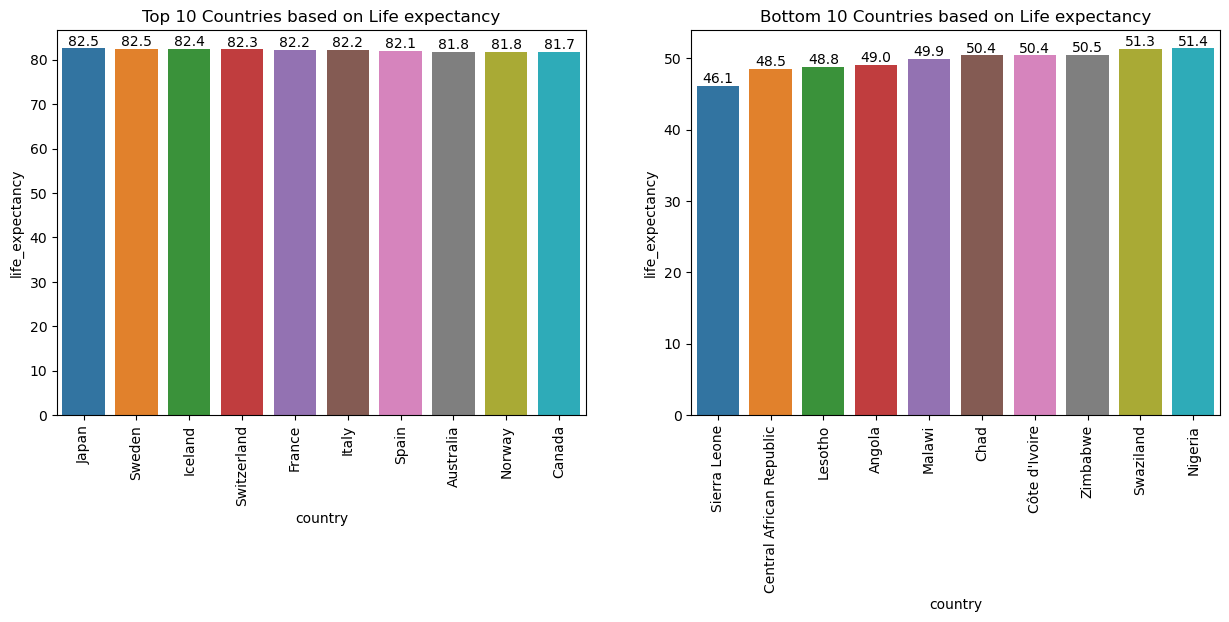

In [43]:
# Display of top and bottom 10 countries on Life expectancy

plt.figure(figsize = (15,5))
plt.subplot(1,2,1)
plt.title('Top 10 Countries based on Life expectancy')
ax1 = sns.barplot(top_data,x = top_data.index, y = 'life_expectancy')
ax1.bar_label(ax1.containers[0], fmt = '%.1f')
plt.xticks(rotation=90)
plt.subplot(1,2,2)

plt.title('Bottom 10 Countries based on Life expectancy')
ax2 = sns.barplot(bottom_data,x = bottom_data.index, y = 'life_expectancy')
ax2.bar_label(ax2.containers[0], fmt = '%.1f')
plt.xticks(rotation=90)
plt.show()

<h5>Observation</h5>
<h6>1.Top 10 Countries:</h6>
Japan has the highest life expectancy at approximately 82.5 years.
Other countries in the top 10 include Switzerland, Australia, Italy, and Spain, all with life expectancies above 81 years.
<h6>2.Bottom 10 Countries:</h6>
Sierra Leone has the lowest life expectancy at around 46.1 years.
Countries with low life expectancies include Central African Republic, Chad, and Nigeria, all below 51 years.

<p>Countries with higher life expectancies often have better healthcare systems, higher standards of living, and more effective public health policies than those with lower life expectancies.</p>
Next I am going to analyse life expectancy with regards to different aspects that might affect it 

<h3>4.2 Life expectancy vs Various aspects</h3>

<h4>Life expectancy vs Alcohol consumption</h4>

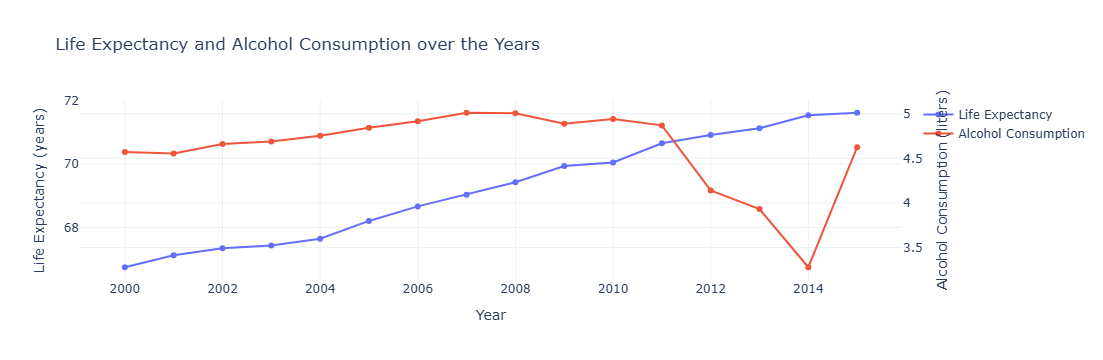

In [47]:
# Calculate the average life expectancy and average alcohol consumption for each year
average_data = df.groupby('year').agg({
    'life_expectancy': 'mean',
    'alcohol': 'mean'
}).reset_index()

# Create the interactive plot with dual y-axes
fig = go.Figure()

# Add life expectancy trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['life_expectancy'], 
                         mode='lines+markers', name='Life Expectancy',
                         yaxis='y1'))

# Add alcohol consumption trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['alcohol'], 
                         mode='lines+markers', name='Alcohol Consumption',
                         yaxis='y2'))

# Update layout for dual y-axes
fig.update_layout(
    title='Life Expectancy and Alcohol Consumption over the Years',
    xaxis=dict(title='Year'),
    yaxis=dict(title='Life Expectancy (years)', side='left'),
    yaxis2=dict(title='Alcohol Consumption (liters)', side='right', overlaying='y'),
    template='plotly_white'
)

# Show the plot
fig.show()

<h4>Life expectancy vs Hepatitis B</h4>

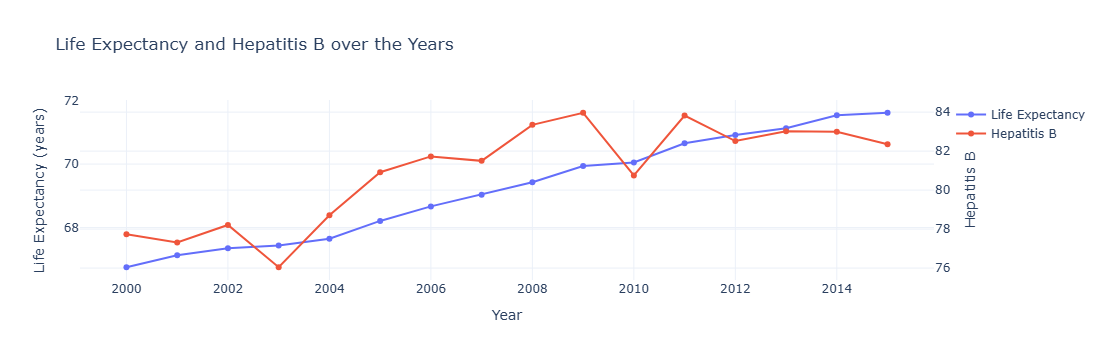

In [49]:
# Calculate the average life expectancy and average HepatitisB for each year
average_data = df.groupby('year').agg({
    'life_expectancy': 'mean',
    'hep_b': 'mean'
}).reset_index()

# Create the interactive plot with dual y-axes
fig = go.Figure()

# Add life expectancy trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['life_expectancy'], 
                         mode='lines+markers', name='Life Expectancy',
                         yaxis='y1'))

# Add hepatitis b trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['hep_b'], 
                         mode='lines+markers', name='Hepatitis B',
                         yaxis='y2'))

# Update layout for dual y-axes
fig.update_layout(
    title='Life Expectancy and Hepatitis B over the Years',
    xaxis=dict(title='Year'),
    yaxis=dict(title='Life Expectancy (years)', side='left'),
    yaxis2=dict(title='Hepatitis B', side='right', overlaying='y'),
    template='plotly_white'
)

# Show the plot
fig.show()

<h4>Life expectancy vs Measles</h4>

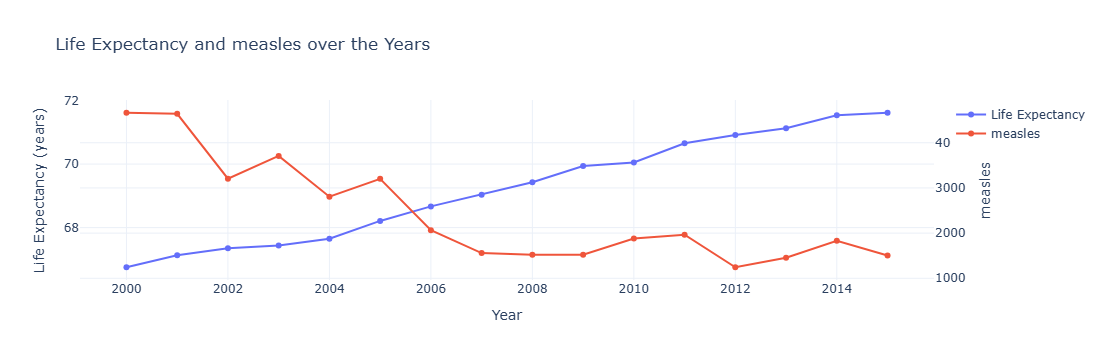

In [51]:
# Calculate the average life expectancy and average measles for each year
average_data = df.groupby('year').agg({
    'life_expectancy': 'mean',
    'measles': 'mean'
}).reset_index()

# Create the interactive plot with dual y-axes
fig = go.Figure()

# Add life expectancy trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['life_expectancy'], 
                         mode='lines+markers', name='Life Expectancy',
                         yaxis='y1'))

# Add measles trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['measles'], 
                         mode='lines+markers', name='measles',
                         yaxis='y2'))

# Update layout for dual y-axes
fig.update_layout(
    title='Life Expectancy and measles over the Years',
    xaxis=dict(title='Year'),
    yaxis=dict(title='Life Expectancy (years)', side='left'),
    yaxis2=dict(title='measles', side='right', overlaying='y'),
    template='plotly_white'
)

# Show the plot
fig.show()

<h4>Life expectancy vs BMI</h4>

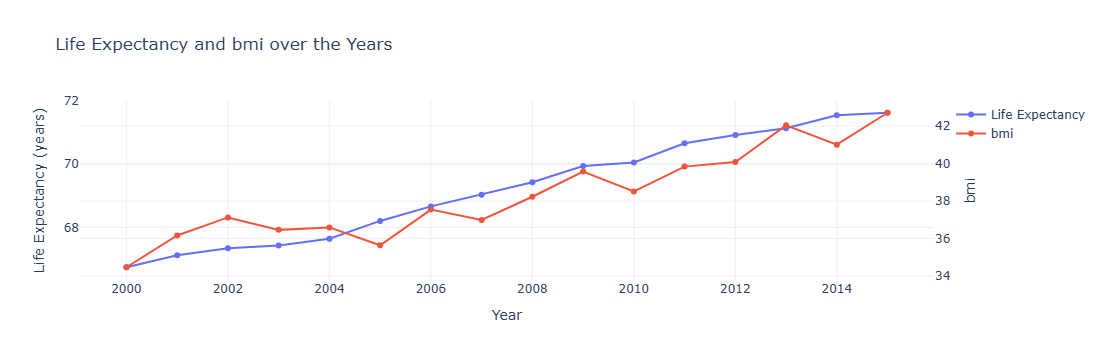

In [53]:
# Calculate the average life expectancy and average bmi for each year
average_data = df.groupby('year').agg({
    'life_expectancy': 'mean',
    'bmi': 'mean'
}).reset_index()

# Create the interactive plot with dual y-axes
fig = go.Figure()

# Add life expectancy trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['life_expectancy'], 
                         mode='lines+markers', name='Life Expectancy',
                         yaxis='y1'))

# Add bmi trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['bmi'], 
                         mode='lines+markers', name='bmi',
                         yaxis='y2'))

# Update layout for dual y-axes
fig.update_layout(
    title='Life Expectancy and bmi over the Years',
    xaxis=dict(title='Year'),
    yaxis=dict(title='Life Expectancy (years)', side='left'),
    yaxis2=dict(title='bmi', side='right', overlaying='y'),
    template='plotly_white'
)

# Show the plot
fig.show()

<h4>Life expectancy vs Polio</h4>

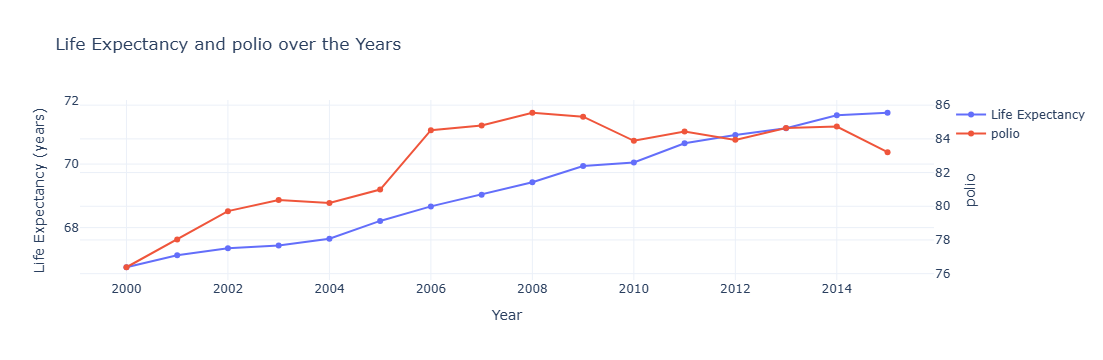

In [55]:
# Calculate the average life expectancy and average polio for each year
average_data = df.groupby('year').agg({
    'life_expectancy': 'mean',
    'polio': 'mean'
}).reset_index()

# Create the interactive plot with dual y-axes
fig = go.Figure()

# Add life expectancy trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['life_expectancy'], 
                         mode='lines+markers', name='Life Expectancy',
                         yaxis='y1'))

# Add polio trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['polio'], 
                         mode='lines+markers', name='polio',
                         yaxis='y2'))

# Update layout for dual y-axes
fig.update_layout(
    title='Life Expectancy and polio over the Years',
    xaxis=dict(title='Year'),
    yaxis=dict(title='Life Expectancy (years)', side='left'),
    yaxis2=dict(title='polio', side='right', overlaying='y'),
    template='plotly_white'
)

# Show the plot
fig.show()

<h4>Life expectancy vs AIDS</h4>

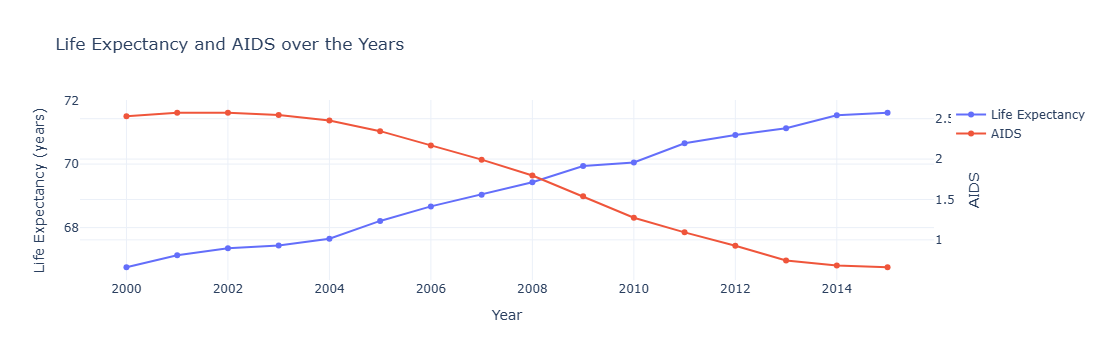

In [57]:
# Calculate the average life expectancy and average aids for each year
average_data = df.groupby('year').agg({
    'life_expectancy': 'mean',
    'aids': 'mean'
}).reset_index()

# Create the interactive plot with dual y-axes
fig = go.Figure()

# Add life expectancy trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['life_expectancy'], 
                         mode='lines+markers', name='Life Expectancy',
                         yaxis='y1'))

# Add aids trace
fig.add_trace(go.Scatter(x=average_data['year'], y=average_data['aids'], 
                         mode='lines+markers', name='AIDS',
                         yaxis='y2'))

# Update layout for dual y-axes
fig.update_layout(
    title='Life Expectancy and AIDS over the Years',
    xaxis=dict(title='Year'),
    yaxis=dict(title='Life Expectancy (years)', side='left'),
    yaxis2=dict(title='AIDS', side='right', overlaying='y'),
    template='plotly_white'
)

# Show the plot
fig.show()

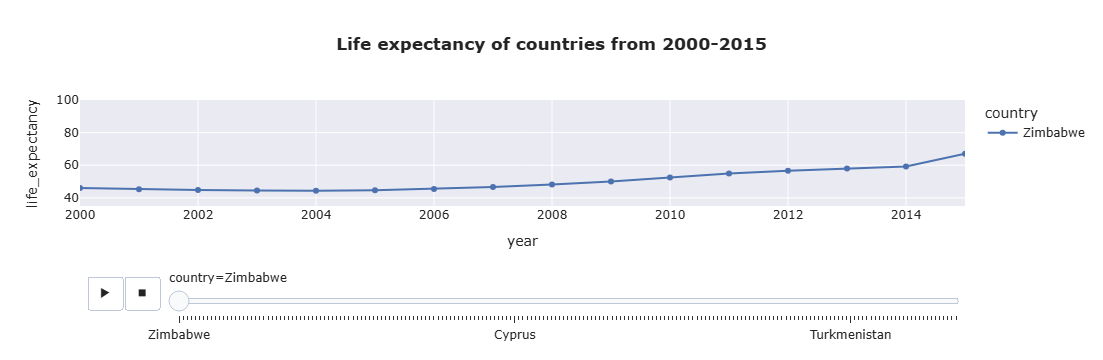

In [58]:
fig = px.line(df.sort_values(by='year'),
              x='year', 
              y='life_expectancy', 
              range_y=[35, 100],
              range_x=[2000, 2015],
              animation_frame='country', 
              animation_group='year', 
              color='country', 
              markers=True, 
              template='seaborn', 
              title='<b>Life expectancy of countries from 2000-2015')
fig.show()


<h3>5. Correlation Analysis</h3>

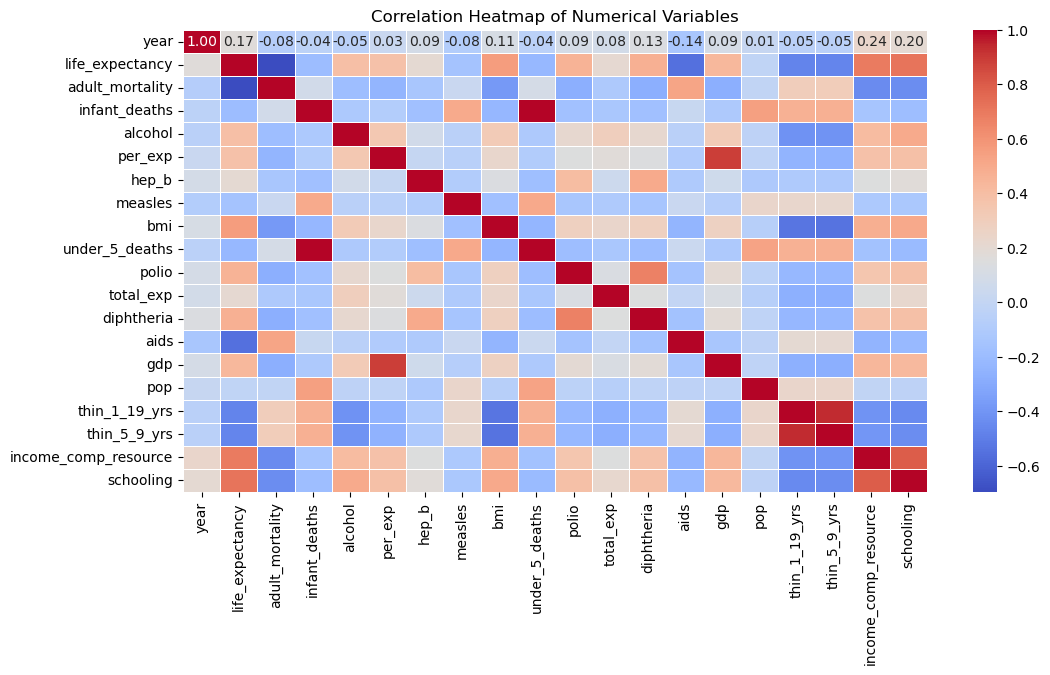

In [60]:
# Selecting only numeric columns
numeric_df = df.select_dtypes(include=['float64', 'int64'])

# Correlation matrix of the numerical columns
corr_matrix = numeric_df.corr()

# Plotting the heatmap for the correlation matrix
plt.figure(figsize=(12, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

<h3>6. Descriptive Analysis</h3>

In [62]:
# Getting summary statistics for the numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,2938.0,2.007519e+03,4.613841e+00,2000.00000,2004.000000,2.008000e+03,2.012000e+03,2.015000e+03
life_expectancy,2938.0,6.922493e+01,9.507640e+00,36.30000,63.200000,7.200000e+01,7.560000e+01,8.900000e+01
adult_mortality,2938.0,1.647964e+02,1.240803e+02,1.00000,74.000000,1.440000e+02,2.270000e+02,7.230000e+02
infant_deaths,2938.0,3.030395e+01,1.179265e+02,0.00000,0.000000,3.000000e+00,2.200000e+01,1.800000e+03
alcohol,2938.0,4.602861e+00,3.916288e+00,0.01000,1.092500,4.160000e+00,7.390000e+00,1.787000e+01
per_exp,2938.0,7.382513e+02,1.987915e+03,0.00000,4.685343,6.491291e+01,4.415341e+02,1.947991e+04
hep_b,2938.0,8.094046e+01,2.258685e+01,1.00000,80.940461,8.700000e+01,9.600000e+01,9.900000e+01
measles,2938.0,2.419592e+03,1.146727e+04,0.00000,0.000000,1.700000e+01,3.602500e+02,2.121830e+05
bmi,2938.0,3.832125e+01,1.992768e+01,1.00000,19.400000,4.300000e+01,5.610000e+01,8.730000e+01
under_5_deaths,2938.0,4.203574e+01,1.604455e+02,0.00000,0.000000,4.000000e+00,2.800000e+01,2.500000e+03


In [63]:
# getting continent name from country
def get_continent(country_name):
    try:
        # Getting the ISO alpha-2 country code
        country_code = pycountry.countries.lookup(country_name).alpha_2
        
        # Converting the country code to continent code
        continent_code = pc.country_alpha2_to_continent_code(country_code)
        # Mapping the continent code to a continent name
        continent_name = pc.convert_continent_code_to_continent_name(continent_code)
        return continent_name
    except:
        return None

# Applying the function to the dataset
df['continent'] = df['country'].apply(get_continent)

# Setting pandas to display all rows
pd.set_option('display.max_rows', None)

# Checking the new column
df[['country', 'continent']]

,country,continent
0,Afghanistan,Asia
1,Afghanistan,Asia
2,Afghanistan,Asia
3,Afghanistan,Asia
4,Afghanistan,Asia
5,Afghanistan,Asia
6,Afghanistan,Asia
7,Afghanistan,Asia
8,Afghanistan,Asia
9,Afghanistan,Asia


In [64]:
# Grouping the data by 'continent' and get the list of countries in each continent
grouped_by_continent = df.groupby('continent')['country'].unique()

# Displaying the grouped countries by continent
print(grouped_by_continent)

continent
Africa           [Algeria, Angola, Benin, Botswana, Burkina Fas...
Asia             [Afghanistan, Armenia, Azerbaijan, Bahrain, Ba...
Europe           [Albania, Austria, Belarus, Belgium, Bosnia an...
North America    [Antigua and Barbuda, Bahamas, Barbados, Beliz...
Oceania          [Australia, Cook Islands, Fiji, Kiribati, Mars...
South America    [Argentina, Brazil, Chile, Colombia, Ecuador, ...
Name: country, dtype: object


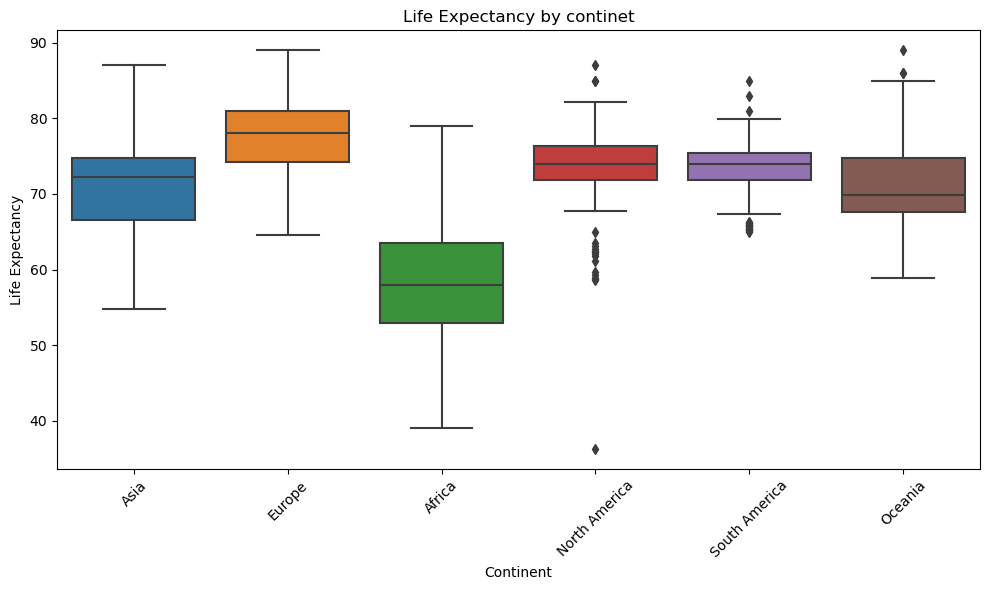

In [65]:
# Set up the plot size
plt.figure(figsize=(10, 6))

# Create the boxplot to show the distribution of life expectancy per region
sns.boxplot(x='continent', y='life_expectancy', data=df)

# Rotate the x-axis labels for better readability
plt.xticks(rotation=45)

# Set the title and labels
plt.title('Life Expectancy by continet')
plt.xlabel('Continent')
plt.ylabel('Life Expectancy')

# Show the plot
plt.tight_layout()
plt.show()

<h5>Observation:</h5>

<p>1.Africa has the lowest life expectancy with a wide variation between countries.</p>
<p>2.North America, Oceania, and Europe have higher and relatively consistent life expectancy values.</p>
<p>3.Asia and South America show moderate life expectancy, with South America having more outliers.</p>
The presence of outliers in North America and South America indicates some countries in these continents have significantly lower life expectancy than others within the same region.


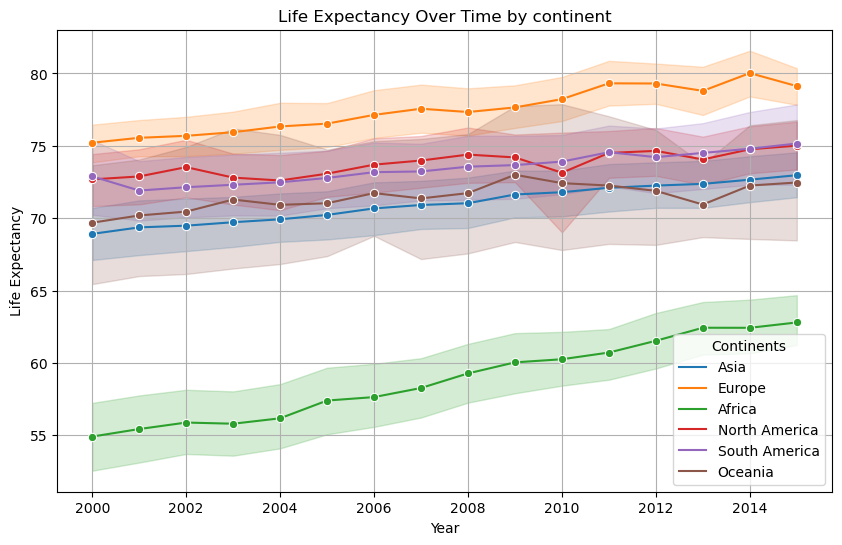

In [67]:
# Create the line plot
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='year', y='life_expectancy', hue='continent', marker='o')

# Add title and labels
plt.title('Life Expectancy Over Time by continent')
plt.xlabel('Year')
plt.ylabel('Life Expectancy')
plt.legend(title='Continents')
plt.grid(True)

# Show the plot
plt.show()

<h5>Observation</h5>
<p>The graph shows the trend of life expectancy from the year 2000 to 2014 for Asia, Africa, Europe, North America, Oceania, and South America.</p>
<p>1.Life expectancy increases across all continents from 2000 to 2014.</p>
<p>2.Europe and Oceania have the highest life expectancies, consistently above 75 years.</p>
<p>3.Africa has the lowest life expectancy, starting below 60 years and showing a gradual increase over time.</p>
<p>4.Asia, North America, and South America fall in between, with life expectancies ranging from the mid-60s to mid-70s.</p>

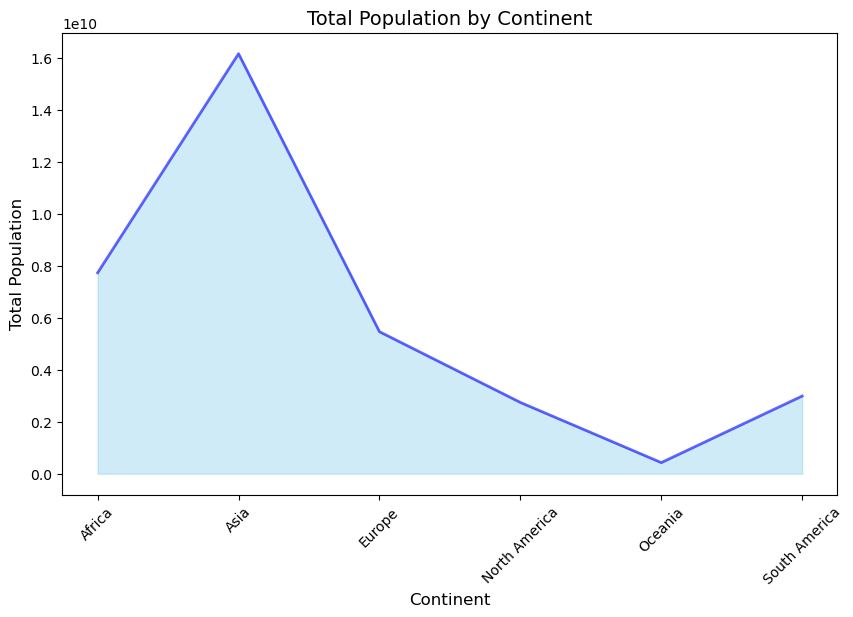

In [69]:
continent_gdp = df.groupby('continent')['pop'].sum()

# Plot the area plot
plt.figure(figsize=(10, 6))
plt.fill_between(continent_gdp.index, continent_gdp, color="skyblue", alpha=0.4)
plt.plot(continent_gdp.index, continent_gdp, color="blue", alpha=0.6, linewidth=2)

# Add labels and title
plt.title('Total Population by Continent', fontsize=14)
plt.xlabel('Continent', fontsize=12)
plt.ylabel('Total Population', fontsize=12)
plt.xticks(rotation=45)
plt.show()

<h3>7. Seasonality and Modelling</h3>

In [71]:
# Perform seasonal decomposition
decomposition = seasonal_decompose(df['life_expectancy'], model='additive', period=5)

# Extracting the components
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

# Displaying the components
print("Trend component:\n", trend.head())
print("\nSeasonal component:\n", seasonal.head())
print("\nResidual component:\n", residual.head())

Trend component:
 0      NaN
1      NaN
2    60.70
3    59.46
4    59.20
Name: trend, dtype: float64

Seasonal component:
 0    0.087300
1    0.076006
2   -0.165579
3   -0.033654
4    0.035928
Name: seasonal, dtype: float64

Residual component:
 0         NaN
1         NaN
2   -0.634421
3    0.073654
4   -0.035928
Name: resid, dtype: float64


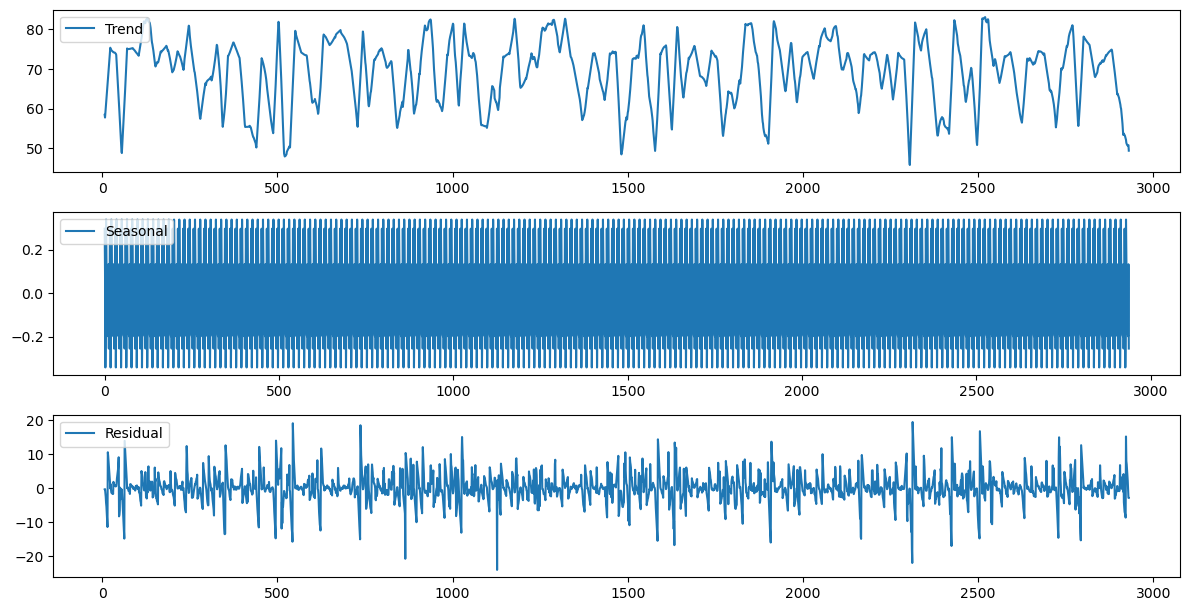

In [72]:
# Perform seasonal decomposition
decomposition = seasonal_decompose(df['life_expectancy'], model='additive', period=15)

trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

# decomposed components plot
plt.figure(figsize=(12, 8))

plt.subplot(411)
plt.plot(trend, label='Trend')
plt.legend(loc='upper left')

plt.subplot(412)
plt.plot(seasonal, label='Seasonal')
plt.legend(loc='upper left')

plt.subplot(413)
plt.plot(residual, label='Residual')
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

<h5>Observation</h5>
1.Trend:
<p>The trend component shows the long-term movement in the data. In this graph, the trend fluctuates between 70 and 80, indicating variability over time. This component helps identify the overall direction in which the data is moving.</p>
2.Seasonal:
<p>The seasonal component captures the repeating patterns or cycles in the data. The values oscillate between approximately -0.2 and 0.2, suggesting a consistent seasonal effect. This component is useful for understanding periodic fluctuations.</p>
3.Residual:
<p>The residual component represents the random noise or irregularities after removing the trend and seasonal effects. The values vary around zero, indicating that the remaining data does not follow a specific pattern.</p>
This type of decomposition is valuable for understanding the underlying patterns in time series data, which can be crucial for forecasting or identifying anomalies.

In [73]:
# Selecting the 'Life expectancy' column for testing
life_expectancy = df['life_expectancy']

# Perform Augmented Dickey-Fuller test
adf_result = adfuller(life_expectancy.dropna())  # Drop NaNs if they exist

# Print ADF test results
print(f'ADF Statistic: {adf_result[0]}')
print(f'p-value: {adf_result[1]}')
for key, value in adf_result[4].items():
    print(f'Critical Values {key}: {value}')

ADF Statistic: -9.265184134261188
p-value: 1.3730526118046359e-15
Critical Values 1%: -3.432591458200774
Critical Values 5%: -2.862530326950686
Critical Values 10%: -2.567297178762432


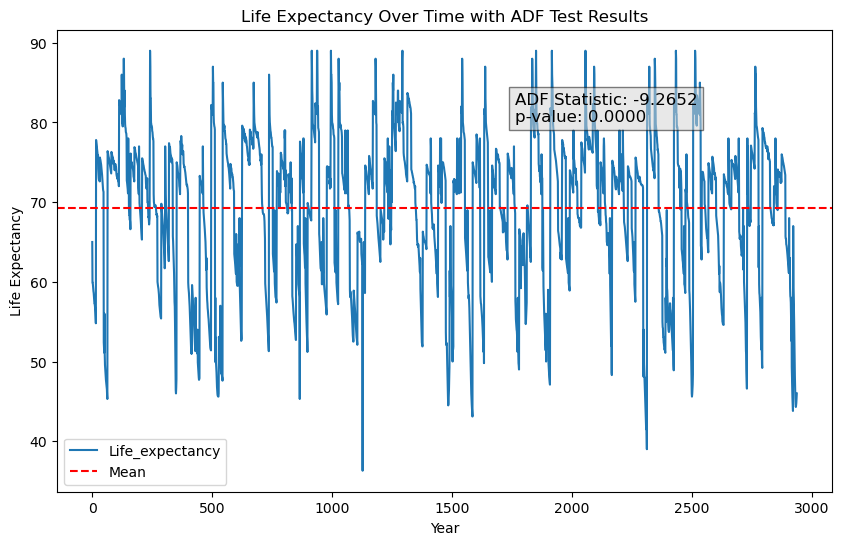

In [74]:
# Plot the time series
plt.figure(figsize=(10, 6))
plt.plot(life_expectancy, label='Life_expectancy')

# Add ADF statistic and p-value to the plot
plt.title('Life Expectancy Over Time with ADF Test Results')
plt.axhline(y=life_expectancy.mean(), color='r', linestyle='--', label='Mean')
plt.text(life_expectancy.index[int(len(life_expectancy) * 0.6)], 
         life_expectancy.max() * 0.9, 
         f'ADF Statistic: {adf_result[0]:.4f}\n' 
         f'p-value: {adf_result[1]:.4f}', 
         fontsize=12, bbox=dict(facecolor='lightgray', alpha=0.5))

# Labels and legend
plt.xlabel('Year')
plt.ylabel('Life Expectancy')
plt.legend()
plt.show()

<h5>Observation</h5>

<b>1.Life Expectancy Trend:</b>
<p>The solid blue line represents life expectancy over time, showing significant fluctuations. The values range from 20 to 90, indicating variability in life expectancy data across the observed period.</p>
<b>2.Mean Line:</b>
<p>The dashed red line represents the mean life expectancy. This provides a reference point to compare the fluctuations in the blue line.</p>
<b>3.ADF Test Results:</b>
<p>The Augmented Dickey-Fuller (ADF) test results are displayed within the graph:</p>
<p>ADF Statistic: -9.2652</p>
<p>p-value: 0.0000</p>
These results suggest that the time series is stationary, meaning it does not have a unit root. A p-value of 0.0000 indicates strong evidence against the null hypothesis of a unit root, confirming the stationarity of the data.

13:38:42 - cmdstanpy - INFO - Chain [1] start processing
13:38:42 - cmdstanpy - INFO - Chain [1] done processing


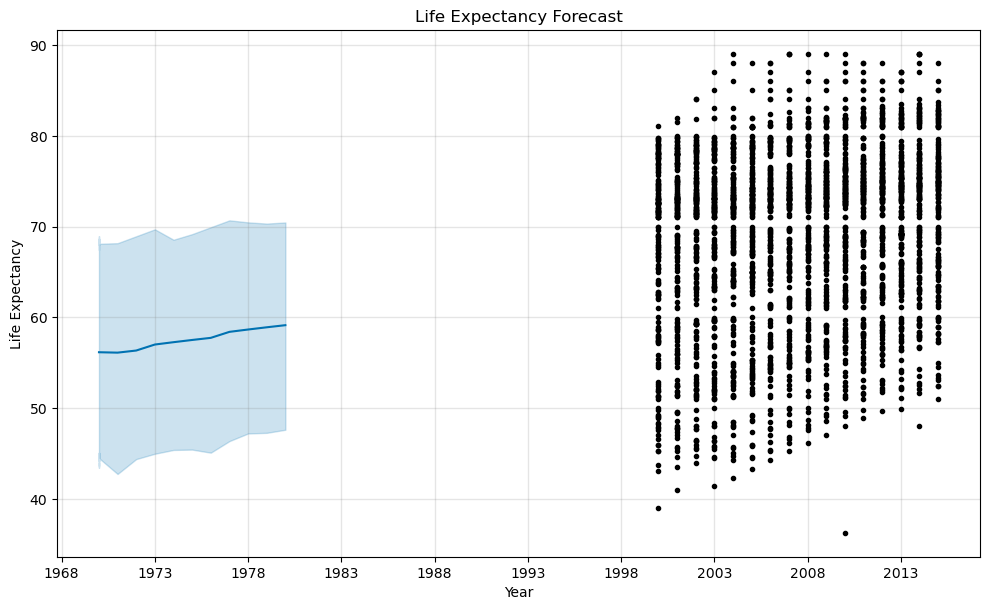

In [75]:
prophet_df = df[['year', 'life_expectancy']].rename(columns={'year': 'ds', 'life_expectancy': 'y'})

# Initialize the model
model = Prophet()

# Fit the model
model.fit(prophet_df)

# Forecast the next 10 years 
future = model.make_future_dataframe(periods=10, freq='Y')

# Make predictions
forecast = model.predict(future)

# Plot the forecast
fig = model.plot(forecast)
plt.title("Life Expectancy Forecast")
plt.xlabel("Year")
plt.ylabel("Life Expectancy")
plt.show()

<h5>Observation</h5>
<b>1.Trend:</b>
<p>The graph shows an overall upward trend in life expectancy from 1968 to 2013. This indicates that life expectancy has generally increased over this period.</p>
<b>2.Data Points and Line of Best Fit:</b>
<p>The scatter plot includes individual data points representing life expectancy for each year.</p>
<p>The line of best fit, which extends across the graph, suggests a positive trend in life expectancy over time.</p>
<b>3.Confidence Interval:</b>
<p>The shaded area around the line of best fit likely represents a confidence interval, indicating the range of uncertainty in the forecast. This helps in understanding the potential variability in future life expectancy predictions.</p>
<b>4.Variability:</b>
<p>The data points are more densely packed in the later years, showing more variability in life expectancy as time progresses.</p>

                               SARIMAX Results                                
Dep. Variable:        life_expectancy   No. Observations:                 2938
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -8017.492
Date:                Tue, 10 Sep 2024   AIC                          16040.984
Time:                        13:38:45   BIC                          16058.940
Sample:                             0   HQIC                         16047.450
                               - 2938                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9222      0.008    108.734      0.000       0.906       0.939
ma.L1         -0.9999      0.026    -37.807      0.000      -1.052      -0.948
sigma2        13.7389      0.383     35.826      0.0

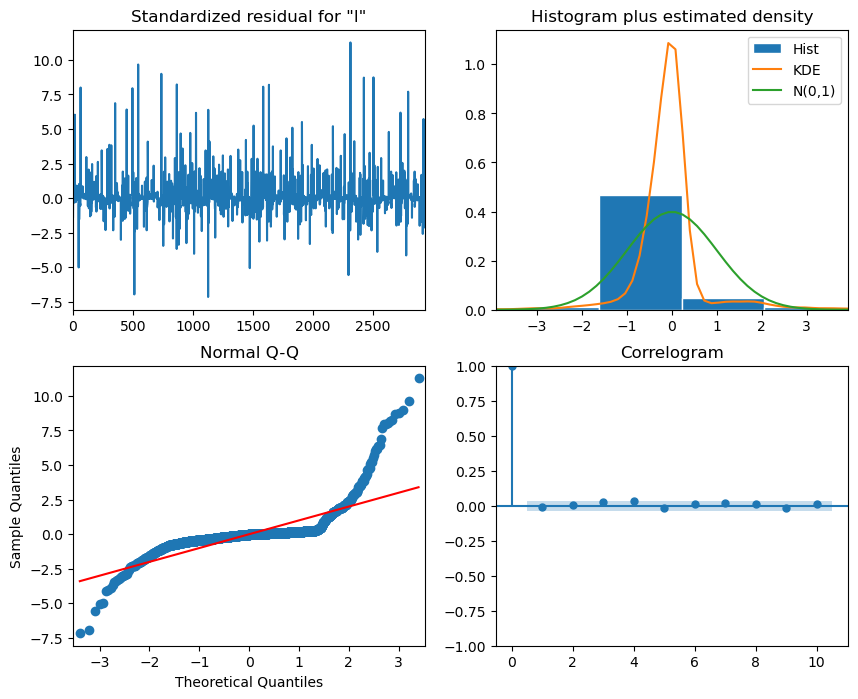

In [76]:
life_expectancy = df['life_expectancy']

# Fit the ARIMA model 
model = ARIMA(life_expectancy, order=(1, 1, 1))
model_fit = model.fit()

# Summary of the model
print(model_fit.summary())

model_fit.plot_diagnostics(figsize=(10, 8))
plt.show()

<h5>Observation</h5>
<b>Model Information Table:</b>
<p>The table at the top includes key metrics for the model such as AIC, BIC, and log likelihood. These metrics help in evaluating the model’s performance and comparing it with other models.</p>
<b>Standardized Residuals for ‘fit’:</b>
<p>This graph shows the residuals plotted against theoretical quantiles with a reference line at zero. It is likely a Q-Q plot used to assess the normality of residuals. If the points closely follow the reference line, it indicates that the residuals are normally distributed.</p>
<b>Histogram of Residuals (plus estimated density):</b>
<p>This histogram displays the frequency distribution of residuals with an overlaid normal distribution curve. It helps in visualizing how well the residuals fit a normal distribution.</p>
<b>Normal Q-Q Plot:</b>
<p>Similar to the first graph, this plot compares data quantiles against normally distributed quantiles. It is another way to check the normality of the residuals.</p>
<b>Correlogram:</b>
<p>This plot shows autocorrelation coefficients at different lags. The blue dots represent the coefficients, and the blue lines indicate significance boundaries. It helps in identifying any autocorrelation in the residuals, which can indicate model inadequacies.</p>

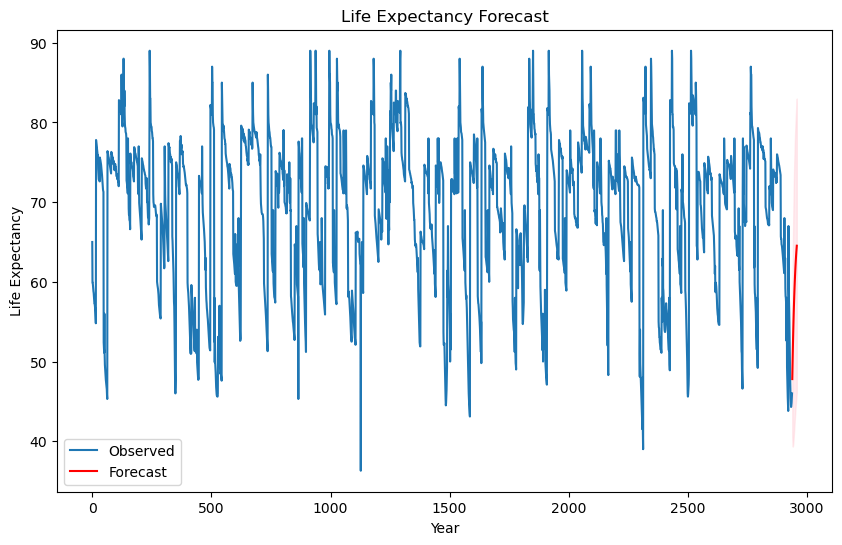

In [77]:
# Forecast for the next 10 years (adjust as needed)
forecast = model_fit.get_forecast(steps=20)

# Get confidence intervals for the forecasted values
forecast_ci = forecast.conf_int()

# Plot the original data
plt.figure(figsize=(10, 6))
plt.plot(life_expectancy, label='Observed')

# Plot the forecast
forecast_values = forecast.predicted_mean
plt.plot(forecast_values.index, forecast_values, color='r', label='Forecast')

# Plot confidence intervals
plt.fill_between(forecast_ci.index,
                 forecast_ci.iloc[:, 0],
                 forecast_ci.iloc[:, 1], color='pink', alpha=0.3)

# Add title and labels
plt.title('Life Expectancy Forecast')
plt.xlabel('Year')
plt.ylabel('Life Expectancy')
plt.legend()

# Show the plot
plt.show()

<h5>Observation</h5>
This graph visually represents past life expectancy trends and projects future expectations, which appear to show a significant decrease

In [78]:
le = LabelEncoder()
cat_cols = df.select_dtypes(include = 'object').columns
for cols in cat_cols:
    df[cols] = le.fit_transform(df[cols])

In [79]:
x =  df.drop(columns='life_expectancy')
y = df['life_expectancy']

In [80]:
scaler = StandardScaler()
cols_to_scale = x.drop(columns='status').columns

# for cols in cols_to_scale:
x[cols_to_scale] = scaler.fit_transform(x[cols_to_scale])

In [81]:
x.head()

,country,year,status,adult_mortality,infant_deaths,alcohol,per_exp,hep_b,measles,bmi,...,total_exp,diphtheria,aids,gdp,pop,thin_1_19_yrs,thin_5_9_yrs,income_comp_resource,schooling,continent
0,-1.691042,1.621762,1,0.791586,0.268824,-1.172958,-0.335570,-0.705861,-0.110384,-0.964715,...,0.925806,-0.732952,-0.323445,-0.525248,0.389975,2.813130,2.773279,-0.725401,-0.579931,-0.460103
1,-1.691042,1.404986,1,0.856072,0.285786,-1.172958,-0.334441,-0.838704,-0.168124,-0.989810,...,0.934140,-0.859877,-0.323445,-0.523083,-0.230936,2.881408,2.817902,-0.740050,-0.610570,-0.460103
2,-1.691042,1.188210,1,0.831890,0.302749,-1.172958,-0.334594,-0.750142,-0.173531,-1.014905,...,0.913306,-0.775260,-0.323445,-0.521632,0.352715,2.926927,2.862526,-0.769349,-0.641209,-0.460103
3,-1.691042,0.971434,1,0.864132,0.328193,-1.172958,-0.332096,-0.617299,0.032045,-1.040000,...,1.075815,-0.648335,-0.323445,-0.518723,-0.168315,2.972446,2.929461,-0.803531,-0.671847,-0.460103
4,-1.691042,0.754658,1,0.888314,0.345155,-1.172958,-0.367862,-0.573018,0.051757,-1.060076,...,0.804966,-0.606027,-0.323445,-0.564893,-0.181666,3.040724,2.974085,-0.847480,-0.763764,-0.460103


<h3>More Models</h3>

In [84]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 30)

In [85]:
print(f"Shape of X_train is: {x_train.shape}")
print(f"Shape of Y_train is: {y_train.shape}\n")
print(f"Shape of X_test is: {x_test.shape}")
print(f"Shape of Y_test is: {y_test.shape}")

Shape of X_train is: (2350, 22)
Shape of Y_train is: (2350,)

Shape of X_test is: (588, 22)
Shape of Y_test is: (588,)


In [86]:
models = {
    'Random Forest': RandomForestRegressor(random_state=42),
    'Extra Trees Regressor': ExtraTreesRegressor(random_state=42),
    'GradientBoost Regressor': GradientBoostingRegressor(random_state=42),
    'XGB Regressor': XGBRegressor()
}

# list to store results
results = []

# Train and evaluate each model
for model_name, model in models.items():
    # Train the model
    model.fit(x_train, y_train)
    
    # Make predictions
    y_pred = model.predict(x_test)
    
    # Calculate metrics
    rmse = mean_squared_error(y_test, y_pred, squared=False)
    r2 = r2_score(y_test, y_pred)
    
    # Store results in list
    results.append({'Model': model_name, 'RMSE': rmse, 'R2 Score': r2})

results_df = pd.DataFrame(results)
results_df=results_df.sort_values("R2 Score", ascending = False)
results_df

,Model,RMSE,R2 Score
1,Extra Trees Regressor,1.898241,0.962615
3,XGB Regressor,1.958910,0.960187
0,Random Forest,2.028328,0.957316
2,GradientBoost Regressor,2.304757,0.944889


<h3>Model comparisons</h3>

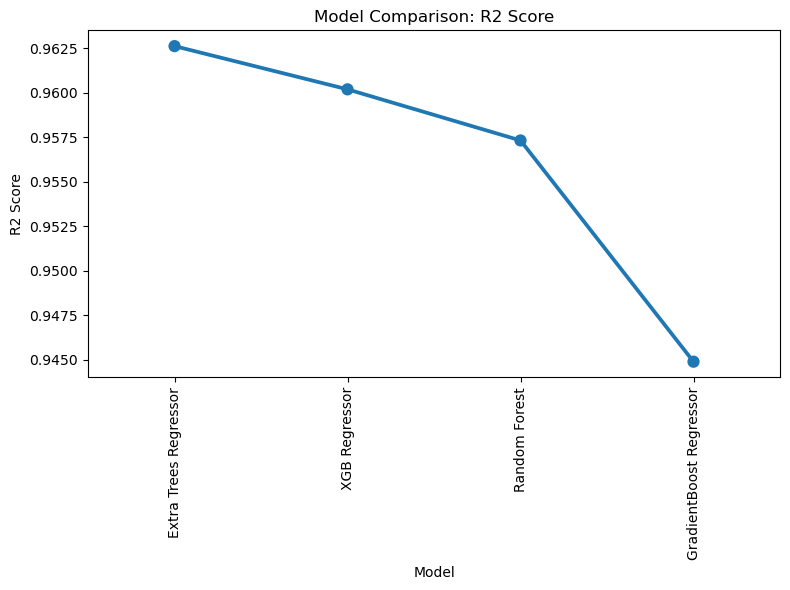

In [88]:
plt.figure(figsize=(8,6))
sns.pointplot(x='Model',y='R2 Score',data=results_df)
plt.xticks(rotation=90)
plt.title('Model Comparison: R2 Score')
plt.tight_layout()
plt.show()

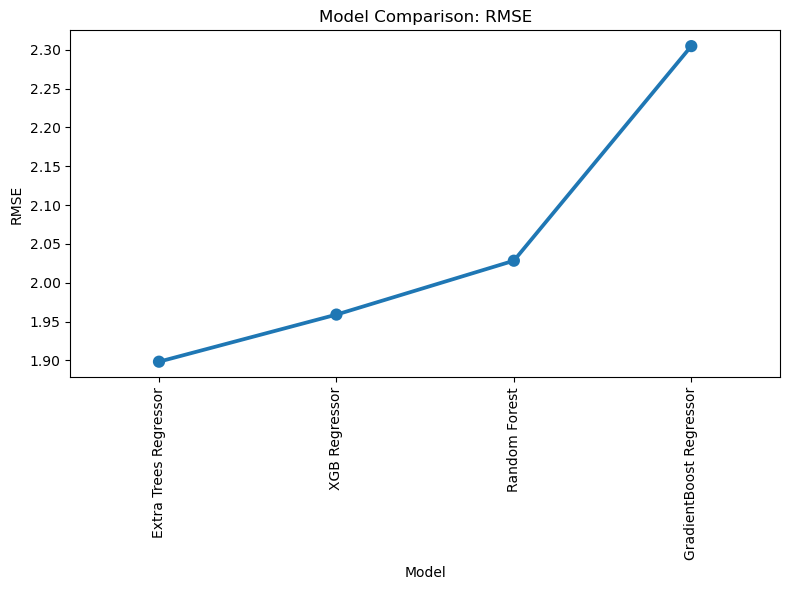

In [89]:
plt.figure(figsize=(8,6))
sns.pointplot(x='Model',y='RMSE',data=results_df)
plt.xticks(rotation=90)
plt.title('Model Comparison: RMSE')
plt.tight_layout()
plt.show()

In [111]:
xgb=XGBRegressor()
xgb.fit(x_train, y_train)
train_pred=xgb.predict(x_train)
test_pred=xgb.predict(x_test)
print("R2 score of train data:", r2_score(y_train, train_pred), sep="\n")
print("Mean squared error of train data:", mean_squared_error(y_train, train_pred), sep="\n")
print("R2 score of test data:", r2_score(y_test, test_pred), sep="\n")
print("Mean squared error of train data:", mean_squared_error(y_test, test_pred), sep="\n")

R2 score of train data:
0.9993300594252693
Mean squared error of train data:
0.05938262812089589
R2 score of test data:
0.960187405583772
Mean squared error of train data:
3.8373272827751292


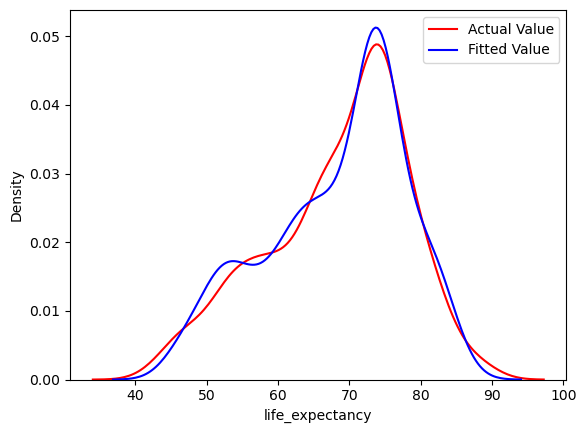

In [115]:
ax=sns.distplot(y_test, hist=False, color="r", label="Actual Value")
sns.distplot(test_pred, hist=False, color="b", ax=ax, label="Fitted Value")
plt.legend(loc="best")
plt.show()

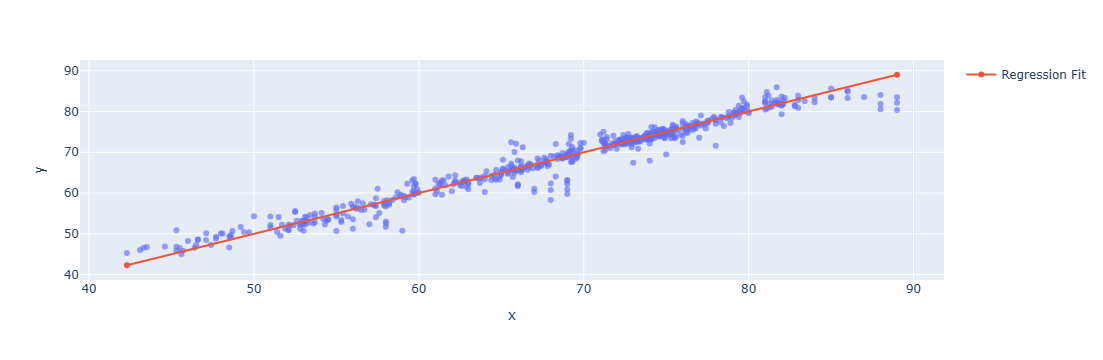

In [117]:
fig = px.scatter(df, x=y_test, y=test_pred, opacity=0.65)
fig.add_traces(go.Scatter(x=[min(y_test), max(y_test)], y=[min(y_test), max(y_test)], name='Regression Fit'))
fig.show()

# 8. Conclusion

This analysis has provided valuable insights into the factors influencing life expectancy across countries. The data highlights key trends and relationships between life expectancy and variables such as GDP, education, healthcare expenditure, and immunization rates. Countries with higher GDP, greater access to education, and stronger healthcare systems tend to experience higher life expectancy, while high rates of adult and infant mortality, low immunization coverage, and poor health infrastructure are common in regions with lower life expectancy.
Developed countries generally have higher life expectancy, reinforcing the importance of socioeconomic factors.
There is a significant disparity in life expectancy between developing and developed countries, which is evident in the statistical analysis.
<h5>Descriptive Analysis:</h5>

The data revealed clear patterns in life expectancy distribution across countries. The distribution plots showed varying trends between developed and developing countries.
From the histograms, some variables such as adult mortality, infant deaths, and alcohol consumption exhibited clear differences between countries with high life expectancies compared to those with lower values.
<h5>Life Expectancy Distribution:</h5>

The pie chart illustrated the countries with life expectancy greater than 85, with notable countries such as Sweden, France, and Australia leading the list. The majority of these countries are developed nations, reinforcing the connection between life expectancy and development status.
The comparison of developed and developing countries demonstrated a shift in the life expectancy distribution. Developed countries generally had higher life expectancies compared to developing countries, confirming socioeconomic disparities.
<h5>Time Series Forecasting:</h5>

By fitting an ARIMA model, we forecasted future life expectancies for selected countries. The forecasts provided useful insights into potential future trends, enabling better planning for public health policy and interventions.
The time series forecast plot gave a clearer perspective on the future trajectory of life expectancy based on historical data, especially for countries with reliable data over long periods.
<h5>Advanced Machine Learning Models:</h5>

Implementing regression models like Random Forest, Gradient Boosting, and XGBoost aimed at predicting life expectancy provided robust performance. These models can further be used to identify important features (e.g., GDP, healthcare spending) that affect life expectancy predictions.